In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
# read in all the words
words = open('names.txt', 'r').read().splitlines()
words[:3]

['emma', 'olivia', 'ava']

In [3]:
len(words)

32035

In [4]:
# build the vocabulary of character mappings to/from integers 
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [5]:
# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):  
  X, Y = [], []
  for w in words:

    #print(w)
    context = [0] * block_size # This used to take the starting value '.' inside the block
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      #print(''.join(itos[i] for i in context), '--->', itos[ix])
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(99)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

# Splitting the dataset into (Training, Validate, Test)
Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

# training split, dev/validation split, test split
# 80%, 10%, 10%

torch.Size([182438, 3]) torch.Size([182438])
torch.Size([22878, 3]) torch.Size([22878])
torch.Size([22841, 3]) torch.Size([22841])


In [6]:
Xtr.shape, Xtr.dtype, Ytr.shape, Ytr.dtype

(torch.Size([182438, 3]), torch.int64, torch.Size([182438]), torch.int64)

In [7]:
C = torch.randn(27,5)
'''NOTE: now to see the vector made in C for our 27 characters we can just use 'C[5]' Which will give us the 5th row from the matrix
   that is the simple way what we can also do is we can use 'F.one_hot()' to convert this into a matrix of dim 27
   where only the 5th element is toggled to 1 other are 0 and we can do matrix multiplication with 'C' this will also create the same result
   following the rersearch paper we stick to lookup.'''

"NOTE: now to see the vector made in C for our 27 characters we can just use 'C[5]' Which will give us the 5th row from the matrix\n   that is the simple way what we can also do is we can use 'F.one_hot()' to convert this into a matrix of dim 27\n   where only the 5th element is toggled to 1 other are 0 and we can do matrix multiplication with 'C' this will also create the same result\n   following the rersearch paper we stick to lookup."

In [8]:
C

tensor([[ 1.4121,  0.5488,  0.2009,  1.1506,  0.2797],
        [-0.0126,  0.4970, -1.3088,  0.0188, -1.0555],
        [ 0.4132, -0.8207, -0.7182,  0.9189, -1.3272],
        [-0.0805,  0.6372,  1.5249,  0.0050, -0.8890],
        [-0.8568,  0.6159, -1.2243, -0.4062,  0.7355],
        [-0.6344,  0.6018, -1.0236,  0.8143,  0.1575],
        [ 2.2016,  0.8482, -0.6751, -0.6658,  0.9549],
        [ 0.3934,  0.2948, -0.8634, -0.6563,  0.7287],
        [-1.3062,  0.6646,  0.5291,  1.5928, -0.9485],
        [ 0.8249,  1.1189,  1.6264,  0.7069, -0.4380],
        [-0.0861,  0.7792,  0.3890, -0.1758,  0.7570],
        [-1.6550,  0.3975, -0.8182,  0.3580, -3.4114],
        [-2.5344, -0.7383,  0.8339,  0.2218, -0.3434],
        [-1.3626,  0.2239, -0.5266, -0.6747,  1.0607],
        [ 0.7837, -0.6563, -2.2659,  1.1279,  0.7817],
        [ 1.0251,  1.4288,  1.3247, -0.8697, -0.6241],
        [-0.0372,  1.4214, -1.5820,  0.3318, -0.8939],
        [ 0.6120,  0.1627, -0.3744, -0.4708, -0.4751],
        [ 

In [9]:
C[5] # Following the paper using this 

tensor([-0.6344,  0.6018, -1.0236,  0.8143,  0.1575])

In [10]:
F.one_hot(torch.tensor(5), num_classes=27).float() @ C

tensor([-0.6344,  0.6018, -1.0236,  0.8143,  0.1575])

In [11]:
# indexing
C[Xtr] # [32, 3, 5]

tensor([[[ 1.4121,  0.5488,  0.2009,  1.1506,  0.2797],
         [ 1.4121,  0.5488,  0.2009,  1.1506,  0.2797],
         [ 1.4121,  0.5488,  0.2009,  1.1506,  0.2797]],

        [[ 1.4121,  0.5488,  0.2009,  1.1506,  0.2797],
         [ 1.4121,  0.5488,  0.2009,  1.1506,  0.2797],
         [ 0.3934,  0.2948, -0.8634, -0.6563,  0.7287]],

        [[ 1.4121,  0.5488,  0.2009,  1.1506,  0.2797],
         [ 0.3934,  0.2948, -0.8634, -0.6563,  0.7287],
         [ 0.8249,  1.1189,  1.6264,  0.7069, -0.4380]],

        ...,

        [[-0.8568,  0.6159, -1.2243, -0.4062,  0.7355],
         [-0.0126,  0.4970, -1.3088,  0.0188, -1.0555],
         [-1.3143, -0.1677,  0.3577, -0.4555,  0.7359]],

        [[-0.0126,  0.4970, -1.3088,  0.0188, -1.0555],
         [-1.3143, -0.1677,  0.3577, -0.4555,  0.7359],
         [-0.0126,  0.4970, -1.3088,  0.0188, -1.0555]],

        [[-1.3143, -0.1677,  0.3577, -0.4555,  0.7359],
         [-0.0126,  0.4970, -1.3088,  0.0188, -1.0555],
         [ 0.7837, -0.65

In [12]:
C[Xtr][13,2]

tensor([-0.0126,  0.4970, -1.3088,  0.0188, -1.0555])

In [13]:
Xtr[13,2]

tensor(1)

In [14]:
C[1]

tensor([-0.0126,  0.4970, -1.3088,  0.0188, -1.0555])

In [15]:
# Layer 1
emb = C[Xtr]
emb.shape

torch.Size([182438, 3, 5])

In [16]:
# Hidden Layer
W1 = torch.randn((15, 150))
b1 = torch.randn(150)

In [17]:
h = torch.tanh(emb.view(-1, 15) @ W1 + b1)

In [18]:
h

tensor([[-0.9960,  0.9999, -0.7558,  ..., -0.9674,  0.9974, -0.2842],
        [-0.3292,  0.9999,  0.3507,  ...,  0.9596, -0.9335,  0.9981],
        [-0.9015, -1.0000, -1.0000,  ..., -1.0000,  0.8884,  0.9864],
        ...,
        [-0.7980, -0.9933, -0.9222,  ...,  0.3660, -0.9996,  1.0000],
        [-0.9639, -0.8900,  0.9417,  ...,  0.9996, -0.9995,  0.9981],
        [-0.3434,  1.0000,  0.9913,  ...,  0.9981, -0.2011,  0.9713]])

In [19]:
h.shape

torch.Size([182438, 150])

In [20]:
# Final Layer
W2 = torch.randn((150, 27))
b2 = torch.randn((27))

In [21]:
logits = h @ W2 + b2

In [22]:
logits.shape 

torch.Size([182438, 27])

In [23]:
counts = logits.exp()

In [24]:
prob = counts / counts.sum(1, keepdims=True)

In [25]:
prob.shape

torch.Size([182438, 27])

In [26]:
# loss = -prob[torch.arange(182566), Ytr].log().mean() # negative log_likelihood
# loss

In [27]:
# ------------ now made respectable :) ---------------

In [28]:
Xtr.shape, Ytr.shape # dataset

(torch.Size([182438, 3]), torch.Size([182438]))

In [29]:
g = torch.Generator().manual_seed(45127676)

C = torch.randn((27, 10), generator=g)
W1 = torch.randn((30, 200), generator=g)
b1 = torch.randn(200, generator=g)
W2 = torch.randn((200, 27), generator=g)
b2 = torch.randn(27, generator=g)

parameters = [C, W1, b1, W2, b2]

In [30]:
sum(p.nelement() for p in parameters) # number of parameters in total

11897

In [31]:
for p in parameters:
  p.requires_grad = True

In [32]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre

In [33]:
lri = []
lossi = []
stepi = []

In [35]:
for i in range(200000):
  
  # Minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (32,))
  
  # Forward pass
  emb = C[Xtr[ix]] # (32, 3, 10)
  h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 200)
  logits = h @ W2 + b2 # (32, 27)
  loss = F.cross_entropy(logits, Ytr[ix])
  
  # Backward pass
  for p in parameters:
    p.grad = None
  loss.backward()
  
  # Update (learning rate decay)
  #lr = lrs[i]
  lr = 0.1 if i < 100000 else 0.01
  for p in parameters:
    p.data += -lr * p.grad

  # Track stats
  #lri.append(lre[i])
  stepi.append(i)
  lossi.append(loss.log10().item())

#print(loss.item())

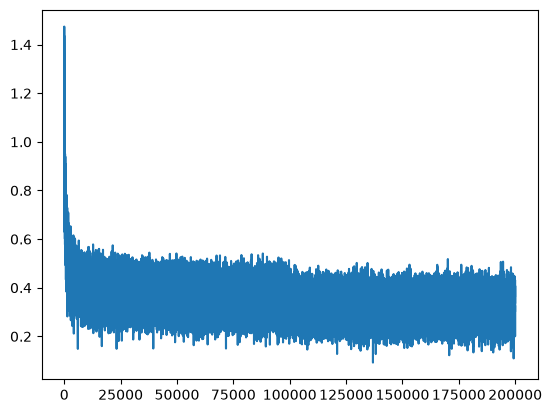

In [36]:
plt.plot(stepi, lossi)

In [37]:
print(loss.item()) # Got very far from the biagram model in terms of loss value

2.1832852363586426


In [38]:
# Networks seen values
emb = C[Xtr] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
loss = F.cross_entropy(logits, Ytr)
loss

tensor(2.1266, grad_fn=<NllLossBackward0>)

In [39]:
# Networks not seen values 
emb = C[Xdev] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
loss = F.cross_entropy(logits, Ydev)
loss

tensor(2.1683, grad_fn=<NllLossBackward0>)

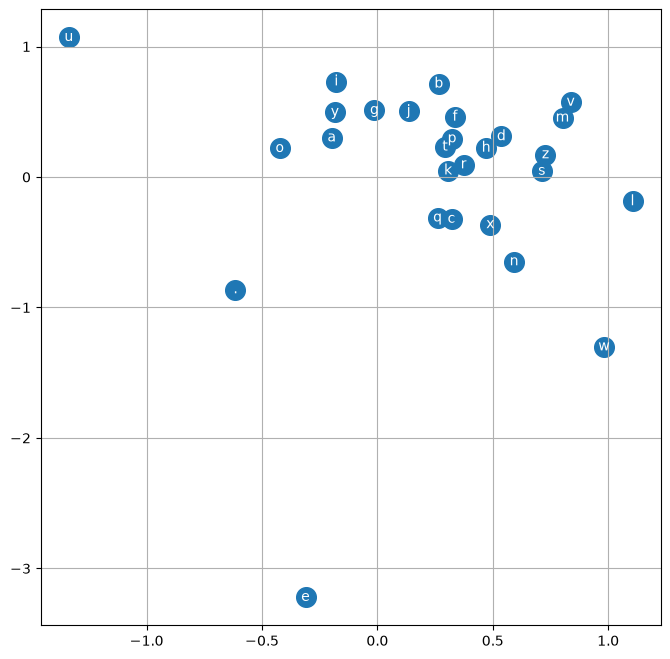

In [40]:
# visualize dimensions 0 and 1 of the embedding matrix C for all characters
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color='white')
plt.grid('minor')

In [41]:
context = [0] * block_size
C[torch.tensor([context])].shape

torch.Size([1, 3, 10])

In [42]:
# sample from the model

for _ in range(20):
    
    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      emb = C[torch.tensor([context])] # (1,block_size,d)
      h = torch.tanh(emb.view(1, -1) @ W1 + b1)
      logits = h @ W2 + b2
      probs = F.softmax(logits, dim=1)
      ix = torch.multinomial(probs, num_samples=1).item()
      context = context[1:] + [ix]
      out.append(ix)
      if ix == 0:
        break
    
    print(''.join(itos[i] for i in out))

goss.
delezlynn.
kyegan.
kholalyndalther.
angze.
ana.
cha.
may.
ehilliiah.
vaver.
khyler.
jah.
elle.
jah.
jayronah.
majael.
harlino.
jayton.
trusta.
yafourieinsley.
